# 01 · Análise descritiva

## Objetivo do projeto

**Antecipar onde a dengue vai aumentar, para que a vigilância em saúde possa agir antes dos casos subirem.**

O projeto responde a três perguntas, cada uma tratada em um notebook:

| Pergunta | Onde |
|---|---|
| 1. Dá para prever os casos de cada município com até 4 semanas de antecedência melhor do que repetindo a semana atual? | Notebook 03 (modelagem) e 02 (significância) |
| 2. O clima ajuda a prever, além do que a época do ano já explica? | Notebook 02 (inferência) |
| 3. Onde e quando o modelo falha? | Notebook 03 (análise de erros) |

## Este notebook

Antes de modelar, este notebook descreve os dados:

1. Os dados são confiáveis? O que falta, o que está atrasado?
2. Como a dengue evolui no tempo e ao longo do ano?
3. Onde ela se concentra: cidades grandes ou pequenas, oeste ou leste?
4. Qual a distribuição dos casos, e o que isso implica para a modelagem?
5. Qual a relação aparente entre clima e casos?

Fonte: API do [InfoDengue](https://info.dengue.mat.br), coletada com `python -m radar_dengue.collect`.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from radar_dengue import style
style.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
from radar_dengue.geo import municipality_table, size_class, PORTES, REGIOES

raw = pd.read_parquet("data/raw/infodengue_sp.parquet")
mun = municipality_table()
d = raw.merge(mun, on="geocode", how="left")
d["ano"] = d["SE"] // 100
d["semana"] = d["SE"] % 100
# porte fixo por município, pela maior população registrada
d["porte"] = size_class(d.groupby("geocode")["pop"].transform("max"))
print(f"{len(d):,} linhas | {d['geocode'].nunique()} municípios | "
      f"{d['data_iniSE'].min():%d/%m/%Y} a {d['data_iniSE'].max():%d/%m/%Y}")
d.head(3)

397,965 linhas | 645 municípios | 04/01/2015 a 25/10/2026


,data_iniSE,SE,casos,casos_est,p_inc100k,nivel,Rt,pop,tempmin,tempmed,...,receptivo,transmissao,geocode,municipio,lon,lat,regiao,ano,semana,porte
0,2015-01-04,201501,3,3.00,8.54,1,7.26,35111,22.29,26.86,...,1,0,3500105,Adamantina,-51.07,-21.58,Oeste,2015,1,20–100 mil
1,2015-01-11,201502,1,1.00,2.85,1,0.85,35111,23.43,29.24,...,0,0,3500105,Adamantina,-51.07,-21.58,Oeste,2015,2,20–100 mil
2,2015-01-18,201503,8,8.00,22.78,1,3.79,35111,22.71,29.00,...,0,1,3500105,Adamantina,-51.07,-21.58,Oeste,2015,3,20–100 mil


## Dicionário das variáveis usadas

| Variável | Significado |
|---|---|
| `data_iniSE`, `SE` | Início e código da semana epidemiológica (ex.: 202414 = semana 14 de 2024) |
| `casos` | Casos notificados na semana (inclui casos prováveis, não só confirmados) |
| `casos_est` | Estimativa do InfoDengue corrigida pelo atraso de notificação (*nowcast*) |
| `p_inc100k` | Incidência estimada por 100 mil habitantes |
| `Rt` | Número reprodutivo: quantas pessoas cada caso infecta |
| `pop` | População do município |
| `tempmin/med/max` | Temperatura mínima, média e máxima da semana (°C) |
| `umidmin/med/max` | Umidade relativa mínima, média e máxima (%) |
| `receptivo`, `transmissao` | Indicadores do InfoDengue de clima favorável e de transmissão sustentada |

## 1. Qualidade dos dados

### 1.1 Valores faltantes

In [2]:
falt = d.groupby("ano")[["casos", "tempmed", "umidmed", "umidmax"]].apply(lambda x: x.isna().mean() * 100)
falt.round(1).rename(columns=lambda c: f"% faltante · {c}")

,% faltante · casos,% faltante · tempmed,% faltante · umidmed,% faltante · umidmax
ano,,,,
2015,0.00,3.30,3.30,1.20
2016,0.00,5.20,5.20,1.80
2017,0.00,25.30,25.30,9.90
2018,0.00,2.60,2.60,0.40
2019,0.00,0.20,0.20,0.00
2020,0.00,10.70,10.70,4.60
2021,0.00,1.00,1.00,0.60
2022,0.00,2.10,2.10,0.10
2023,0.00,0.10,0.10,0.00


Os **casos nunca faltam**. O clima tem lacunas, concentradas em **2017 (25% das semanas)** e 2020 (11%),
provavelmente falhas das estações meteorológicas usadas pelo InfoDengue. Na modelagem, cada lacuna é
preenchida com o valor da semana anterior do mesmo município (`ffill`), o que é razoável para clima,
que muda devagar.

### 1.2 Semanas com zero casos

In [3]:
zeros = d.groupby("porte", observed=True).agg(
    municipios=("geocode", "nunique"), pct_semanas_zero=("casos", lambda s: (s == 0).mean() * 100))
zeros

,municipios,pct_semanas_zero
porte,,
<20 mil,379,60.09
20–100 mil,184,31.31
100–500 mil,73,10.59
>500 mil,9,1.55


**60% das semanas das cidades com menos de 20 mil habitantes têm zero casos.** Como elas são a
maioria dos 645 municípios, a base é dominada por zeros. Isso tem duas consequências: (1) erros percentuais não
fazem sentido nessas cidades (dividir por zero), por isso usamos erro absoluto e escala logarítmica;
(2) a incidência por 100 mil habitantes é instável em cidades pequenas: 3 casos em 3 mil habitantes
já são 100 por 100 mil.

### 1.3 Atraso de notificação

In [4]:
estado = d.groupby("data_iniSE")[["casos", "casos_est"]].sum()
ult = estado.tail(8).copy()
ult["% já notificado"] = ult["casos"] / ult["casos_est"] * 100
ult.round(0)

,casos,casos_est,% já notificado
data_iniSE,,,
2026-09-06,3710,"3,729.00",99.00
2026-09-13,3931,"3,970.00",99.00
2026-09-20,4897,"4,967.00",99.00
2026-09-27,5270,"5,394.00",98.00
2026-10-04,4833,"5,058.00",96.00
2026-10-11,4962,"5,414.00",92.00
2026-10-18,4430,"5,498.00",81.00
2026-10-25,1239,"4,448.00",28.00


Um caso de uma semana continua chegando ao sistema nas semanas seguintes. Na semana mais recente,
apenas **cerca de 28% dos casos estimados já tinham sido notificados**. Se usássemos esses números
brutos, o modelo veria uma "queda" que não existe. Por isso:

- na **avaliação**, as 4 últimas semanas ficam de fora (ainda não são a verdade);
- na **previsão**, as semanas recentes usam o `casos_est` do InfoDengue.

## 2. Evolução no tempo

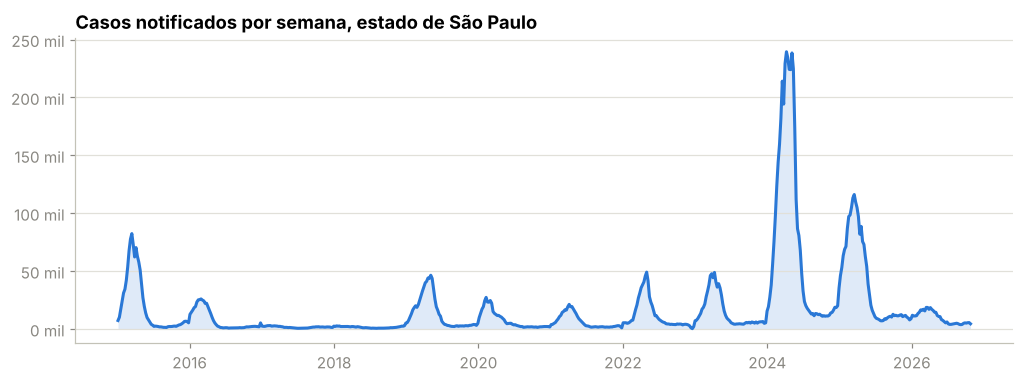

,casos,incidencia_100k,variação vs ano anterior (%)
ano,,,
2015,"1,032,689","2,244",+nan
2016,"398,252",865,-61
2017,"83,640",182,-79
2018,"78,099",170,-7
2019,"718,360","1,561",+820
2020,"396,495",861,-45
2021,"339,165",737,-14
2022,"632,915","1,375",+87
2023,"778,926","1,692",+23


In [5]:
fig, ax = plt.subplots(figsize=(11, 3.6))
serie = estado["casos"].where(estado.index < estado.index.max() - pd.Timedelta(weeks=3), estado["casos_est"])
ax.fill_between(serie.index, serie.values, color=style.OBSERVADO, alpha=0.15, linewidth=0)
ax.plot(serie.index, serie.values, color=style.OBSERVADO)
ax.set_title("Casos notificados por semana, estado de São Paulo")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f} mil")
plt.show()

anual = (d[d["ano"] < 2026].groupby("ano")
         .agg(casos=("casos", "sum"))
         .assign(incidencia_100k=lambda t: t["casos"] / d[d["ano"] == 2024].groupby("geocode")["pop"].max().sum() * 1e5))
anual["variação vs ano anterior (%)"] = anual["casos"].pct_change() * 100
anual.style.format({"casos": "{:,.0f}", "incidencia_100k": "{:,.0f}", "variação vs ano anterior (%)": "{:+.0f}"})

- A dengue em SP alterna **anos epidêmicos** (2015, 2019, 2022–2025) e **anos de baixa** (2017–2018).
- **2024 foi a maior epidemia da série**: cerca de 3,9 milhões de casos notificados, quase 5 vezes 2023.
  A semana de 7 de abril de 2024 teve sozinha cerca de 239 mil casos.
- 2025 também foi grande (cerca de 2 milhões). Em 2026, até outubro, o ano foi de baixa.

Para a modelagem, isso significa que o **período de teste (2024 em diante) tem valores muito acima de
tudo o que o modelo viu no treino**. É um teste difícil, e realista.

## 3. Sazonalidade

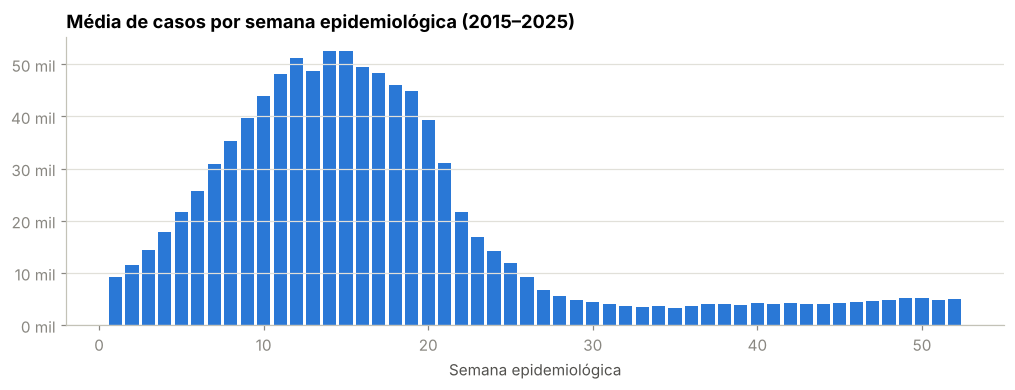

,semana do pico,casos no pico
ano,,
2015,11,82353
2016,9,25931
2017,7,2944
2018,52,2781
2019,19,46404
2020,7,27261
2021,14,21228
2022,18,49090
2023,15,48839


In [6]:
hist = d[d["ano"] < 2026]
media_semana = hist.groupby("semana")["casos"].sum() / hist["ano"].nunique()
media_semana = media_semana[media_semana.index <= 52]

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(media_semana.index, media_semana.values, color=style.OBSERVADO, width=0.8)
ax.set_title("Média de casos por semana epidemiológica (2015–2025)")
ax.set_xlabel("Semana epidemiológica")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f} mil")
plt.show()

pico = (d.groupby(["ano", "semana"])["casos"].sum().reset_index()
        .sort_values("casos").groupby("ano").tail(1).sort_values("ano"))
pico.rename(columns={"semana": "semana do pico", "casos": "casos no pico"}).set_index("ano")

O ciclo é muito regular: a dengue cresce de janeiro a março, **atinge o pico entre as semanas 7 e 19
(fevereiro a maio; na média de todos os anos, semana 14)** e cai a quase zero de julho a outubro. A exceção é 2018, ano de
casos tão baixos que o "pico" caiu em dezembro.

Esse padrão explica por que a **época do ano** entra no modelo, codificada como seno e cosseno da
semana. Assim o modelo entende que a semana 52 fica ao lado da semana 1.

## 4. Onde a dengue se concentra

### 4.1 Por porte do município

In [7]:
pop_porte = d[d["ano"] == 2024].groupby(["porte", "geocode"], observed=True)["pop"].max().groupby("porte", observed=True).sum()
casos_porte = d[d["ano"].between(2015, 2025)].groupby(["porte", "ano"], observed=True)["casos"].sum().unstack()
inc_porte = casos_porte.div(pop_porte, axis=0) * 1e5
inc_porte[[2019, 2022, 2023, 2024, 2025]].round(0)

ano,2019,2022,2023,2024,2025
porte,,,,,
<20 mil,"2,707.00","3,674.00","3,706.00","7,092.00","5,855.00"
20–100 mil,"2,320.00","2,023.00","2,699.00","8,024.00","6,080.00"
100–500 mil,"1,945.00","1,633.00","1,853.00","7,312.00","5,155.00"
>500 mil,767.00,563.00,859.00,"9,961.00","3,212.00"


Em incidência (casos por 100 mil habitantes), **cidades pequenas e médias costumam ter taxas maiores
que as grandes**. A exceção é 2024, quando os municípios acima de 500 mil habitantes, puxados pela
capital, lideraram, um primeiro sinal do que a seção 4.2 mostra. Em números absolutos, porém, os 9 municípios com mais de 500 mil
habitantes concentram boa parte dos casos. Por isso as métricas de erro em número de casos são
dominadas pelas cidades grandes, e é importante olhar também o erro por porte (notebook 03).

### 4.2 Por região

A região é uma aproximação por faixas de longitude do centróide de cada município:
**Oeste** (a oeste de -50°, interior noroeste e Alta Paulista), **Centro** (entre -50° e -48°) e
**Leste** (a leste de -48°: Grande São Paulo, Campinas, Vale do Paraíba e litoral).

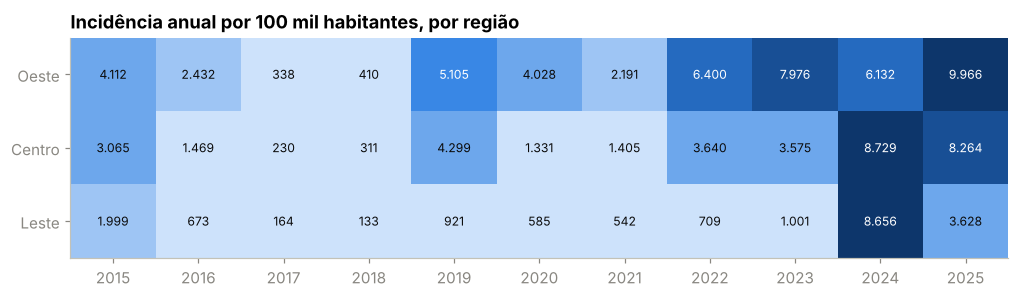

In [8]:
pop_reg = d[d["ano"] == 2024].groupby(["regiao", "geocode"], observed=True)["pop"].max().groupby("regiao", observed=True).sum()
casos_reg = d[d["ano"] < 2026].groupby(["regiao", "ano"], observed=True)["casos"].sum().unstack()
inc_reg = casos_reg.div(pop_reg, axis=0) * 1e5

fig, ax = plt.subplots(figsize=(11, 2.6))
im = ax.imshow(inc_reg.values, aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(style.RAMPA))
ax.set_yticks(range(3), inc_reg.index); ax.set_xticks(range(inc_reg.shape[1]), inc_reg.columns)
for i in range(inc_reg.shape[0]):
    for j in range(inc_reg.shape[1]):
        v = inc_reg.values[i, j]
        ax.text(j, i, f"{v:,.0f}".replace(",", "."), ha="center", va="center", fontsize=8,
                color="white" if v > inc_reg.values.max() * 0.45 else "#0b0b0b")
ax.grid(False); ax.set_title("Incidência anual por 100 mil habitantes, por região")
plt.show()

Este é um dos achados mais interessantes da descritiva:

- O **Oeste** é a região **endêmica**: incidência alta quase todo ano (entre 6 e 10 mil por 100 mil
  habitantes nos anos epidêmicos recentes).
- O **Leste** historicamente tinha pouca dengue (menos de mil por 100 mil em 2022 e 2023), mas em
  **2024 sua incidência multiplicou por cerca de 9** e se igualou ao interior.

Ou seja, a epidemia de 2024 foi recorde principalmente porque **chegou com força à região mais
populosa do estado**, onde a população tinha pouca imunidade prévia. Isso ajuda a explicar por que
modelos treinados no passado tendem a subestimar 2024.

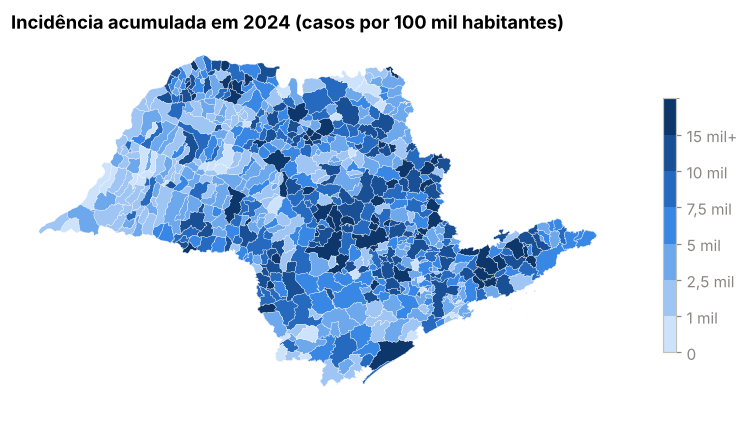

In [9]:
from matplotlib.colors import BoundaryNorm, ListedColormap
inc24 = (d[d["ano"] == 2024].groupby("geocode").agg(c=("casos", "sum"), p=("pop", "max"))
         .eval("c / p * 1e5").to_dict())
bounds = [0, 1000, 2500, 5000, 7500, 10000, 15000, 1e9]
cmap = ListedColormap(style.RAMPA); norm = BoundaryNorm(bounds, cmap.N)
fig, ax = plt.subplots(figsize=(9, 5))
style.plot_map(ax, inc24, cmap, norm)
sm_ = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cb = fig.colorbar(sm_, ax=ax, shrink=0.6, ticks=bounds[:-1])
cb.ax.set_yticklabels(["0", "1 mil", "2,5 mil", "5 mil", "7,5 mil", "10 mil", "15 mil+"])
ax.set_title("Incidência acumulada em 2024 (casos por 100 mil habitantes)")
plt.show()

## 5. Distribuição dos casos

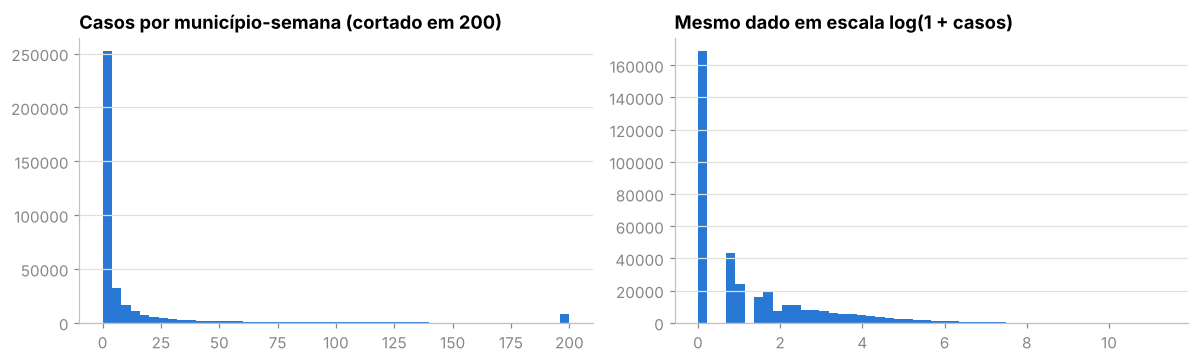

Razão variância/média (mediana entre municípios): 44


In [10]:
semanal = d[d["ano"] < 2026]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(semanal["casos"].clip(upper=200), bins=50, color=style.OBSERVADO)
axes[0].set_title("Casos por município-semana (cortado em 200)")
axes[1].hist(np.log1p(semanal["casos"]), bins=50, color=style.OBSERVADO)
axes[1].set_title("Mesmo dado em escala log(1 + casos)")
plt.tight_layout(); plt.show()

disp = semanal.groupby("geocode")["casos"].agg(["mean", "var"])
disp = disp[disp["mean"] > 0]
print(f"Razão variância/média (mediana entre municípios): {(disp['var'] / disp['mean']).median():,.0f}")

A distribuição é **extremamente assimétrica**: a maioria das semanas tem poucos casos e algumas têm
milhares. Na escala logarítmica ela fica muito mais bem comportada. Dois usos disso:

- O modelo de previsão trabalha com **log(1 + casos)**, para que cidades grandes não dominem o
  aprendizado.
- A variância é dezenas de vezes maior que a média (**sobredispersão**). Uma regressão de Poisson,
  que supõe variância igual à média, seria inadequada. Por isso o notebook 02 usa a
  **binomial negativa**.

## 6. Clima e dengue: o que os dados mostram à primeira vista

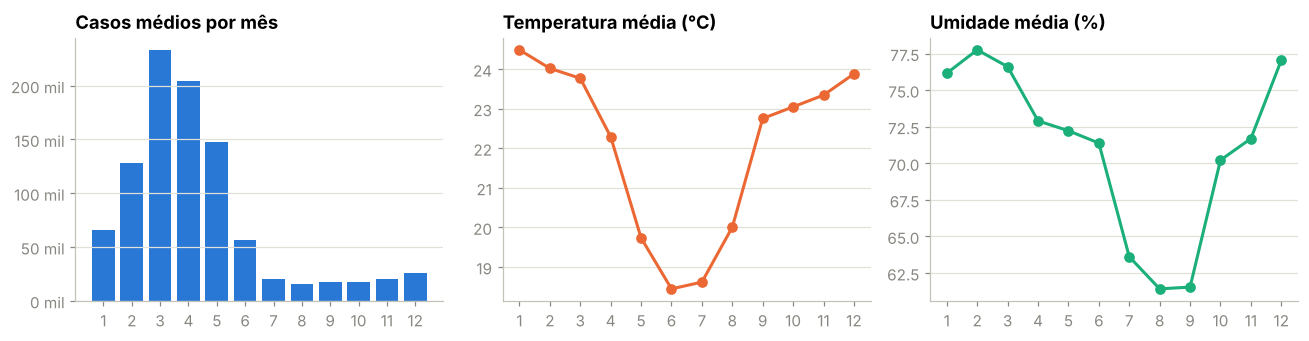

In [11]:
mensal = d[d["ano"] < 2026].assign(mes=d["data_iniSE"].dt.month)
clima_mes = mensal.groupby("mes")[["tempmed", "umidmed"]].mean()
casos_mes = mensal.groupby("mes")["casos"].sum() / mensal["ano"].nunique()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].bar(casos_mes.index, casos_mes.values, color=style.OBSERVADO); axes[0].set_title("Casos médios por mês")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f} mil")
axes[1].plot(clima_mes.index, clima_mes["tempmed"], color=style.PREVISTO, marker="o"); axes[1].set_title("Temperatura média (°C)")
axes[2].plot(clima_mes.index, clima_mes["umidmed"], color=style.TERCEIRA, marker="o"); axes[2].set_title("Umidade média (%)")
for a in axes: a.set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

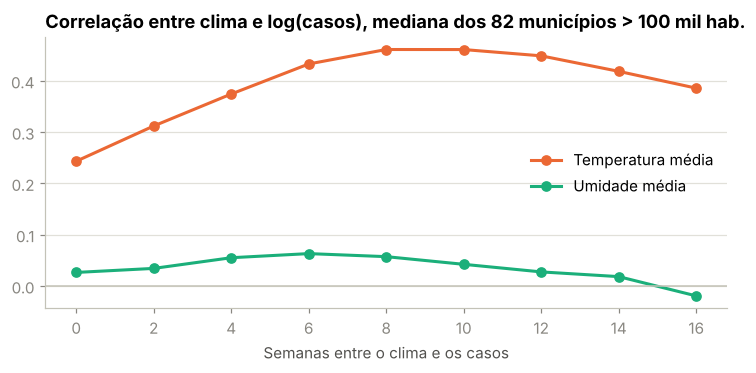

,corr. temperatura,corr. umidade
defasagem (semanas),,
0,0.24,0.03
2,0.31,0.03
4,0.37,0.06
6,0.43,0.06
8,0.46,0.06
10,0.46,0.04
12,0.45,0.03
14,0.42,0.02
16,0.39,-0.02


In [12]:
grandes = d[d["pop"] > 100e3].sort_values(["geocode", "data_iniSE"]).copy()
grandes["log_casos"] = np.log1p(grandes["casos"])
linhas = []
for lag in range(0, 17, 2):
    g = grandes.groupby("geocode")
    grandes["t"] = g["tempmed"].shift(lag); grandes["u"] = g["umidmed"].shift(lag)
    linhas.append({"defasagem (semanas)": lag,
                   "corr. temperatura": grandes.groupby("geocode").apply(lambda x: x["log_casos"].corr(x["t"])).median(),
                   "corr. umidade": grandes.groupby("geocode").apply(lambda x: x["log_casos"].corr(x["u"])).median()})
lags = pd.DataFrame(linhas).set_index("defasagem (semanas)")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(lags.index, lags["corr. temperatura"], color=style.PREVISTO, marker="o", label="Temperatura média")
ax.plot(lags.index, lags["corr. umidade"], color=style.TERCEIRA, marker="o", label="Umidade média")
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_xlabel("Semanas entre o clima e os casos"); ax.set_title("Correlação entre clima e log(casos), mediana dos 82 municípios > 100 mil hab.")
ax.legend(); plt.show()
lags.round(2)

A temperatura parece ter uma relação forte com os casos, **mais forte cerca de 8 a 10 semanas
depois** (correlação mediana de 0,46). Isso bate com a biologia: o calor acelera o ciclo do
mosquito e do vírus, e há várias semanas entre a chuva e calor, a multiplicação do *Aedes* e o pico de
casos. A umidade quase não se correlaciona.

**Cuidado, porém:** temperatura e dengue são ambas sazonais. As duas sobem no verão e caem no
inverno, então seriam correlacionadas mesmo que uma não influenciasse a outra. O notebook 02 testa se
a temperatura explica algo **além da época do ano**.

## Resumo dos achados

1. **Dados de casos completos**; clima com lacunas em 2017 e 2020, preenchidas com a semana anterior.
2. **Atraso de notificação forte** nas últimas semanas: exige *nowcast* na previsão e exclusão na avaliação.
3. **Sazonalidade marcante**, com pico por volta da semana 14 (abril).
4. **2024 foi excepcional** e atingiu principalmente o Leste, região de baixa imunidade prévia.
5. **Distribuição assimétrica e sobredispersa**, com muitos zeros: justifica escala log, erro absoluto e binomial negativa.
6. **Clima correlacionado com casos 8 a 10 semanas depois**, mas possivelmente confundido pela sazonalidade.